# CS156 Assignment #1: Implementation

Code for the reminder classifier. The write-up lives in `write-up.ipynb`.

The Telegram export and the CSVs contain personal messages, so they live in `data/` and are gitignored. Some are in the notebook in the form of prints intentionally and with their PII removed. 

## 1. Data

The data consists of all the messages I've sent to my OpenClaw, filtered to messages sent after the first 2 days, as those are mostly setup related.

I extracted them from Telegram using their 'Chat export' feature on the Desktop app that makes a .html with all the conversation history between me and the agent.

The notebook parses this history for turns where USER_NAME = "Stiven Triana" and writes them to the following schema in a csv:
```
    id                  SHA-256 hash of the message text
    message             the raw text I sent
    has_remind_keyword  1 if the text matches the regex \bremind\w*, else 0
    timestamp           when the message was sent (ISO 8601)
    label               reminder = 1, other = 0
```

I chose a hash-based id to have a unique way to distinguish messages from one another. has_remind_keyword is meant to serve as a baseline for counting and comparing the naive approach with other methods. label is NOT determined from has_remind_keyword, as some messages are reminder related but don't have 'remind' on them. I also removed individual messages that didn't have meaningful information with a filler word filter, e.g. if a message only consisted of 'yes' or 'go ahead'.

Messages from the first days (assistant setup) and messages that are only a filler reply ("yes", "lgtm") are dropped.


In [2]:
import hashlib
import re
from datetime import datetime, timedelta
from pathlib import Path

import pandas as pd
from bs4 import BeautifulSoup

HTML_PATH = Path("data/messages.html")
CSV_PATH = Path("data/messages.csv")
USER_NAME = "Stiven Triana"
REMIND_PATTERN = re.compile(r"\bremind\w*", re.IGNORECASE)
TIMESTAMP_FORMAT = "%d %B %Y, %H:%M:%S"
CSV_COLUMNS = ["id", "message", "has_remind_keyword", "timestamp", "label"]
SETUP_DAYS = 2
FILLER_PHRASES = {
    "yes", "no", "y", "n", "yep", "yeah", "yup", "nope", "nah",
    "ok", "okay", "k", "kk", "sure", "go ahead", "do it", "sounds good",
    "lgtm", "thanks", "thank you", "thx", "ty", "cool", "nice", "great",
    "perfect", "done", "continue", "proceed", "correct", "right",
    "fine", "approved", "confirmed", "hey", "hi", "hello",
}

In [4]:
# 1. Read my messages out of the Telegram export
soup = BeautifulSoup(HTML_PATH.read_text(encoding="utf-8"), "html.parser")
messages = []
sender = ""
for message_div in soup.select("div.message.default"):
    name_div = message_div.select_one("div.from_name")
      # follow-up messages from the same sender leave the name out
    if name_div:
        sender = name_div.get_text().strip()
    text_div = message_div.select_one("div.body > div.text")
    # Skip messages from the assistant 
    if sender != USER_NAME or not text_div:
        continue

    # Telegram writes line breaks in a message as <br> tags, which get_text() would
    # drop and glue the lines together, so turn each one into a real newline first
    for line_break in text_div.find_all("br"):
        line_break.replace_with("\n")
    text = text_div.get_text().strip()
    # Skip messages with no text (e.g. photo's or audio messages), then save the
    # message with the time it was sent
    if text:
        sent_at = message_div.select_one("div.date")["title"]
        messages.append({"message": text, "timestamp": datetime.strptime(sent_at, TIMESTAMP_FORMAT)})

df = pd.DataFrame(messages)
print(f"user messages: {len(df)}")

# 2. Drop the first days (mostly setting up the assistant)
df = df[df["timestamp"] >= df["timestamp"].min() + timedelta(days=SETUP_DAYS)]
print(f"after dropping first {SETUP_DAYS} days: {len(df)}")

# 3. Drop messages that are only a filler reply like "yes" or "lgtm"
cleaned = df["message"].str.lower().str.replace(r"[^\w\s]", " ", regex=True).str.split().str.join(" ")
df = df[~cleaned.isin(FILLER_PHRASES)]
print(f"after dropping filler replies: {len(df)}")

# 4. Drop duplicates, and add the other columns
df = df.assign(id=df["message"].map(lambda text: hashlib.sha256(text.encode("utf-8")).hexdigest()))
df = df.drop_duplicates("id")
df["has_remind_keyword"] = df["message"].str.contains(REMIND_PATTERN).astype(int)
df["timestamp"] = df["timestamp"].dt.strftime("%Y-%m-%dT%H:%M:%S")
df["label"] = ""
print(f"after dedup: {len(df)}")
print(f"has_remind_keyword=1: {df['has_remind_keyword'].sum()}")

# 5. Save, unless the CSV is already written and has labels
has_labels = CSV_PATH.exists() and (pd.read_csv(CSV_PATH, dtype=str, keep_default_na=False)["label"] != "").any()
if has_labels:
    print("csv already written and already has labels. Skipping overwrite")
else:
    df[CSV_COLUMNS].to_csv(CSV_PATH, index=False)
    print(f"\ncsv written to {CSV_PATH} with {len(df)} rows")

user messages: 679
after dropping first 2 days: 563
after dropping filler replies: 559
after dedup: 558
has_remind_keyword=1: 238

csv written to data\messages.csv with 558 rows


This left me with the following message counts:

| Stage | Messages |
|---|---|
| All messages I sent | 679 |
| After removing the first 2 days | 563 |
| After removing filler replies (e.g. "yes", "lgtm") | 559 |
| After de-duplicating by hash | 558 |
| Matching the `has_remind_keyword` regex | 238 |

## 2. Labelling

I needed a way to ```label``` my messages that didn't send them to a cloud provider, didn't require me manually going through each one, and would know when a message was a reminder even if it didn't contain remind on it (e.g. 'lmk at 7 my assignment is due').

I resorted to using Perplexity's pre-trained decision model 'Decider' v1.1 at 27B on my computer using Ollama. It is the best benchmarked model on classification tasks I could run on my laptop ([source](https://artificialanalysis.ai/articles/artificial-analysis-decision-index)). I sent each message to the model with the same prompt, providing it some examples of messages that constitute a reminder, from the obvious to the ambiguous. The model's verdict resulted in the ```label``` column (one could say I'm distilling the model's intelligence into a smaller, personalized version for my task). It took 32 minutes to process all messages and it labelled 257 as reminder-related out of 558.

In [17]:
import time

import requests

# Start ollama with ollama serve
# If it gives an error:
# Error: listen tcp 127.0.0.1:11434: bind: Only one usage of each socket address (protocol/network address/port) is normally permitted.
# Then curl the address to verify it already is running there
OLLAMA_URL = "http://localhost:11434"
OLLAMA_MODEL = "pplx-decider"
MAX_ATTEMPTS = 3
REQUEST_TIMEOUT_SECONDS = 300
QUESTION_NAME = "reminder_request"
CHOICE_TO_LABEL = {"reminder": 1, "other": 0}
INSTRUCTIONS = "The state is a message a user sent to their personal AI assistant. Is it a request related to reminders? I.e., to set a reminder, change a reminder, or otherwise reminder related?"

REMINDER = "The user asks to be reminded of something at a specific time or after a delay, once or on a recurring schedule, or asks to create, change, list or cancel such reminders. Examples: 'remind me to clean my room at 21' or 'At 9, let me know to check whether my package has arrived' or 'what reminders have I set today?' or 'in 20min let me know the toaster is done'."

OTHER = "The user's request is NOT related to reminders, or it mentions words related to them but isn't a reminder ask. Examples: 'that reminds me of a song. who sings it?' or 'can you find if Best Buy closes before 21?' or 'i like this quote, save it: “Every sunset reminds me that endings can be beautiful.”'."

LABEL_QUESTION = {
    "type": "choice",
    "instructions": INSTRUCTIONS,
    "criteria": {"reminder": REMINDER, "other": OTHER},
}

In [18]:
def label_message(message: str) -> int | None:
    """Ask the model about one message. Returns 1, 0, or None if every attempt failed."""
    payload = {
        "model": OLLAMA_MODEL,
        "state": message,
        "questions": {QUESTION_NAME: LABEL_QUESTION},
    }
    # Retries just in case 
    for attempt in range(1, MAX_ATTEMPTS + 1):
        response_text = ""
        try:
            response = requests.post(
                f"{OLLAMA_URL}/v1/systemone", json=payload, timeout=REQUEST_TIMEOUT_SECONDS
            )
            response_text = response.text
            choice = response.json()["answers"][QUESTION_NAME]["choice"]
        except (requests.RequestException, ValueError, KeyError, TypeError) as error:
            print(f"\nattempt {attempt}/{MAX_ATTEMPTS} failed: {type(error).__name__}: {error} | response: {response_text[:200]!r}")
            continue

        label = CHOICE_TO_LABEL.get(choice)

        # Check the label is something
        if label is not None:
            return label
        print(f"\nattempt {attempt}/{MAX_ATTEMPTS}: unexpected choice {choice!r}")
    return None


def label_all_messages(csv_path: Path) -> int:
    """Label every row that has no label yet, saving after each one. Returns the failure count."""
    # Read the dataset
    dataset = pd.read_csv(csv_path, dtype=str, keep_default_na=False)

    # Check which rows have already been labelled
    already_labelled = dataset["label"].value_counts()
    print(
        f"already labelled: {already_labelled.get('1', 0)} reminder, "
        f"{already_labelled.get('0', 0)} other (skipped)"
    )

    total_rows = len(dataset)
    labelled_before = int((dataset["label"] != "").sum())
    labelled_now = 0
    failures = 0
    start_time = time.perf_counter()
    # Start labelling
    for row_index, row in dataset.iterrows():
        if row["label"] != "":
            continue

        # Label an individual message using a helper functino
        label = label_message(row["message"])

        # Count failures
        if label is None:
            failures += 1
            continue

        dataset.at[row_index, "label"] = str(label)
        dataset.to_csv(csv_path, index=False)

        # Count successes
        labelled_now += 1
        labelled_total = labelled_before + labelled_now
        print(f"\r{labelled_total}/{total_rows} labelled so far", end="", flush=True)
    print()
    print(f"labelling took {time.perf_counter() - start_time:.1f}s")
    return failures

In [19]:
failed = label_all_messages(CSV_PATH)
labels = pd.read_csv(CSV_PATH, dtype=str, keep_default_na=False)["label"]
print(f"model: {OLLAMA_MODEL}")
print(f"label=1: {(labels == '1').sum()}, label=0: {(labels == '0').sum()}")
print(f"unlabelled after {MAX_ATTEMPTS} attempts each: {failed}")

already labelled: 0 reminder, 0 other (skipped)
558/558 labelled so far
labelling took 1929.5s
model: pplx-decider
label=1: 257, label=0: 301
unlabelled after 3 attempts each: 0


The ```label``` column disagreed with the ```has_remind_keyword``` column 4.8% of the time, 27 times out of 558.

4 out of 27 are false positives, where the regex picked up the word reminder but that wasn't my intent. For example, a prompt asking how the model sets the reminders I ask it to set internally.

23 out of 27 were false negatives, where the regex did not pick up the word but I had a reminder-related ask. For example: 'and add one at 12:45 to go w/`<redacted>` team to eat here: https://www.jazzcultural.com'. Most of the false negatives were follow ups to when I was setting many reminders at a time. There were also some that were requests to add an event to my calendar, but I don't really use that anymore and would rather it does so as a reminder, so I consider labelling them as a reminder ask correct.

I care about avoiding false positives because I wouldn't want unrelated, possibly complex prompts to go to an underpowered model, so it was good to validate that the regex approach, even if mostly accurate, wasn't perfect.

Last, I replaced some PII like names and places with `<redacted>`, and fully redacted three messages that had sensitive information in them.

I chose to use the model labels for training because they better captured edge cases after review. I also figured it to be a good experiment: can I distill the intelligence of a much bigger, costly, and slow model into a simple classifier function?

In [73]:
# Messages where the keyword regex and the model disagree
MAX_MESSAGE_CHARS = 200

labelled = pd.read_csv(CSV_PATH, dtype=str, keep_default_na=False)
disagreements = labelled[(labelled["has_remind_keyword"] == "1") != (labelled["label"] == "1")]

total = len(labelled)
regex_reminders = (labelled["has_remind_keyword"] == "1").sum()
model_reminders = (labelled["label"] == "1").sum()
print(f"regex: {regex_reminders} reminder, {total - regex_reminders} other")
print(f"model: {model_reminders} reminder, {total - model_reminders} other")
print(f"disagreement: {len(disagreements) / total:.1%}")
print(f"disagreements: {len(disagreements)} of {total}")
print()

# Opinions come first so they never scroll out of view
for number, (_, row) in enumerate(disagreements.iterrows(), start=1):
    regex_opinion = "reminder" if row["has_remind_keyword"] == "1" else "other"
    model_opinion = "reminder" if row["label"] == "1" else "other"
    text = " ".join(row["message"].split())[:MAX_MESSAGE_CHARS]
    print(f"{number:>2} | regex: {regex_opinion:<8} | model: {model_opinion:<8} | {text}")

regex: 238 reminder, 320 other
model: 257 reminder, 301 other
disagreement: 4.8%
disagreements: 27 of 558

 1 | regex: other    | model: reminder | Also add to my calendar this sunday to visit park avenue armory between 12 - 7pm
 2 | regex: other    | model: reminder | On my calendar, on august 2nd, add to plan a Patagonia trip with <redacted>
 3 | regex: other    | model: reminder | now done, stop that cron
 4 | regex: other    | model: reminder | and add one at 12:45 to go w/<redacted> team to eat here: https://www.jazzcultural.com
 5 | regex: other    | model: reminder | Add to my calendar pls Item Details Venue Subtotal Total <redacted> 1 x Ben Davis: Can San Francisco Become The Florence Of A New Renaissance? - Thursday, September 10th, 2026 at 6:00 PM PDT - Registr
 6 | regex: other    | model: reminder | Ok so, now onto the sauce: I want you to set up a daily cron at 9am that has you or a subagent check for deals on restaurants ! Basically, i want to get my moneys worth and chec

## 3. Split

80% of the messages go to training and 20% to testing. The split is stratified on `label`, so both groups keep the same share of reminders, and the seed is fixed so it is the same every run. The test set is only used for the final evaluation.

I split the dataset with 80% of messages in the train set and 20% in the test set. I wanted to make sure each set had a similar share of roughly 50/50 of each class, so I used the stratify argument in sklearn's train_test_split with `label`. This resulted in a training set of 446 messages (205 reminder, 241 other) and a test set of 112 messages (52 reminder, 60 other).

In [113]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.2
# Insider reference :)
RANDOM_SEED = 94102

dataset = pd.read_csv(CSV_PATH, dtype=str, keep_default_na=False)
train, test = train_test_split(
    dataset, test_size=TEST_SIZE, stratify=dataset["label"], random_state=RANDOM_SEED
)

for name, group in [("train", train), ("test", test)]:
    reminders = (group["label"] == "1").sum()
    print(f"{name}: {len(group)} messages ({reminders} reminder, {len(group) - reminders} other)")

train: 446 messages (205 reminder, 241 other)
test: 112 messages (52 reminder, 60 other)


# 4. Tokenization

TF-IDF table with one row per message and one column per word following the code from Session 5.

As a binary classification problem, logistic regression seemed like a good fit. Looking back at the PCW for session 5, we did this for the SMS classification problem with a TF-IDF table. It made sense to use one for this problem too, since it downweights filler words, so I used sklearn to vectorize the data into a TF-IDF and worked with this format for the models I tried: logistic regression and naive Bayes.

In [114]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()
X_train = vectorizer.fit_transform(train["message"])

print(f"vocabulary: {X_train.shape[1]} words, train {X_train.shape}")

vocabulary: 1883 words, train (446, 1883)


# 5. Model training

In [115]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

model = LogisticRegression()
model.fit(X_train, train["label"])

print(f"train loss (log loss): {log_loss(train['label'], model.predict_proba(X_train)):.4f}")
print(f"train accuracy: {model.score(X_train, train['label']):.1%}")

train loss (log loss): 0.2687
train accuracy: 97.5%


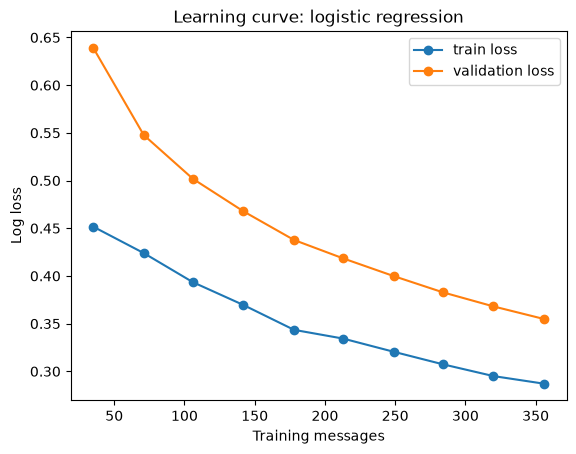

In [124]:
# Wanted to see if the model learnt mostly early or if more data helps
# The plots below train on a increasing number of messages and plots the log loss 
# There is a clear downward curve, suggesting more data would could take the loss down further 
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import learning_curve

train_sizes, train_scores, validation_scores = learning_curve(
    LogisticRegression(), X_train, train["label"],
    train_sizes=np.linspace(0.1, 1.0, 10), cv=5, scoring="neg_log_loss",
)

plt.plot(train_sizes, -train_scores.mean(axis=1), marker="o", label="train loss")
plt.plot(train_sizes, -validation_scores.mean(axis=1), marker="o", label="validation loss")
plt.xlabel("Training messages")
plt.ylabel("Log loss")
plt.title("Learning curve: logistic regression")
plt.legend()
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/learning_curve_logistic.png", dpi=150, bbox_inches="tight")
plt.show()

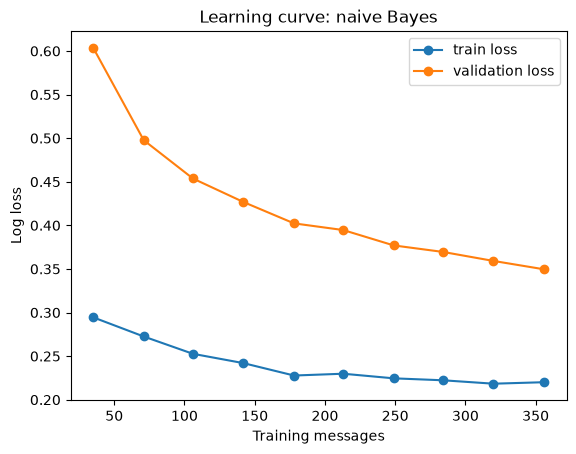

In [117]:
# Same learning curve for naive Bayes
from sklearn.naive_bayes import MultinomialNB

train_sizes, train_scores, validation_scores = learning_curve(
    MultinomialNB(), X_train, train["label"],
    train_sizes=np.linspace(0.1, 1.0, 10), cv=5, scoring="neg_log_loss",
)

plt.plot(train_sizes, -train_scores.mean(axis=1), marker="o", label="train loss")
plt.plot(train_sizes, -validation_scores.mean(axis=1), marker="o", label="validation loss")
plt.xlabel("Training messages")
plt.ylabel("Log loss")
plt.title("Learning curve: naive Bayes")
plt.legend()
plt.savefig("figures/learning_curve_naive_bayes.png", dpi=150, bbox_inches="tight")
plt.show()

# 6. Model validation

Used some more of the visualization code from the Session 5 PCW for the confusion matrix and the learned word weights. 

In [118]:
# Scores on the test set for accuracy, precision and recall
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn import metrics

X_test = vectorizer.transform(test["message"])
pred_labels = model.predict(X_test)

print(f"test accuracy: {metrics.accuracy_score(test['label'], pred_labels):.1%}")
print(f"test precision: {metrics.precision_score(test['label'], pred_labels, pos_label='1'):.1%}")
print(f"test recall: {metrics.recall_score(test['label'], pred_labels, pos_label='1'):.1%}")

test accuracy: 96.4%
test precision: 96.2%
test recall: 96.2%


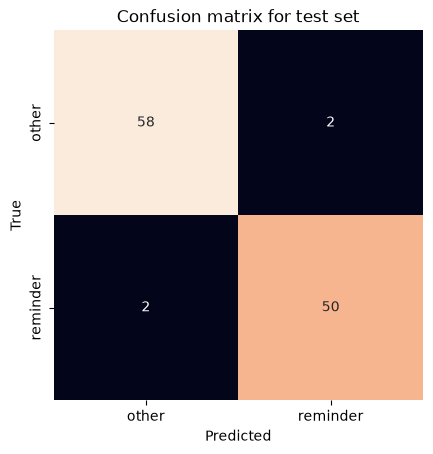

In [119]:
# Confusion matrix: how many messages does the model get wrong for each class?
confusion_mat = metrics.confusion_matrix(test["label"], pred_labels)
class_names = ["other", "reminder"]  # label 0, label 1
sns.heatmap(confusion_mat, square=True, annot=True, fmt="d", cbar=False, xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix for test set")
plt.savefig("figures/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [120]:
# Print the test messages that the model got wrong with its true/predicted class pair
for message, true, predicted in zip(test["message"], test["label"], pred_labels):
    if true != predicted:
        print(f"true: {class_names[int(true)]:<8} | predicted: {class_names[int(predicted)]:<8} | {message.replace(chr(10), ' ')}")

true: reminder | predicted: other    | <redacted>
true: reminder | predicted: other    | Yeah add it to the reminder
true: other    | predicted: reminder | At 11:30
true: other    | predicted: reminder | to cold email <redacted>


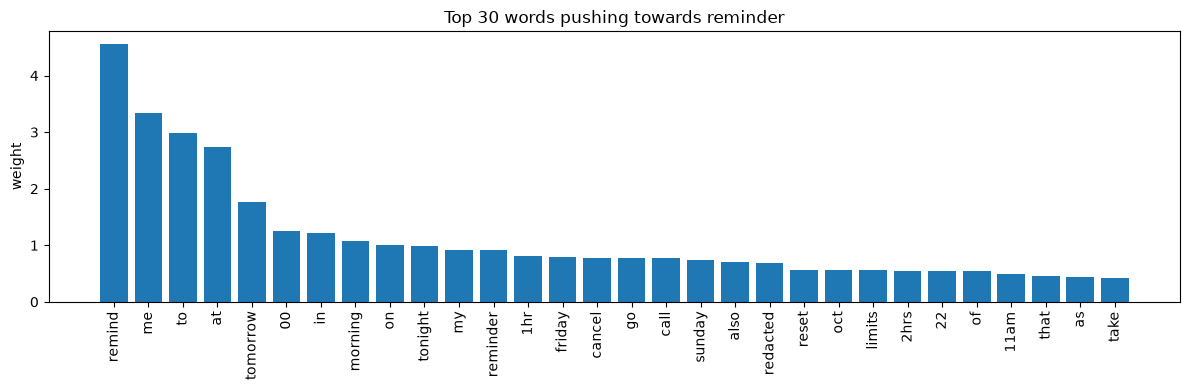

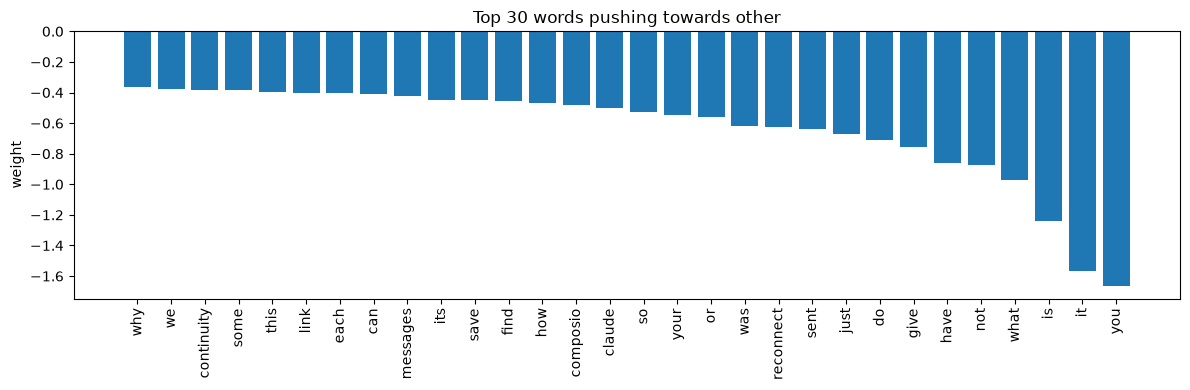

In [121]:
# Visualize the top learned weights per word for both classes
inv = {v: k for k, v in vectorizer.vocabulary_.items()}
weights = model.coef_[0]
order = np.argsort(-weights)
top, bot = order[:30], order[-30:]
plt.figure(figsize=(12,4)); plt.bar([inv[i] for i in top], weights[top]); plt.xticks(rotation=90); plt.ylabel("weight"); plt.title("Top 30 words pushing towards reminder"); plt.tight_layout(); plt.show()
plt.figure(figsize=(12,4)); plt.bar([inv[i] for i in bot], weights[bot]); plt.xticks(rotation=90); plt.ylabel("weight"); plt.title("Top 30 words pushing towards other"); plt.tight_layout(); plt.show()

In [ ]:
# Take it for a test run!
test_strings = [
                "msg me abt this in 2hrs", 
                "remind me at 20 to take the trash out", 
                "remind remind remind",
                "Can you cancel that reminder",
                "Can u cancel that reminder",
                "try a string here!",
                ]

for sample, probability in zip(test_strings, model.predict_proba(vectorizer.transform(test_strings))[:, 1]):
    verdict = "reminder" if probability > 0.5 else "other"
    confidence = f"({probability:.1%} reminder)"
    print(f"{verdict:<8} {confidence:<17} | {sample}")

reminder (58.3% reminder)  | msg me abt this in 2hrs
reminder (89.6% reminder)  | remind me at 20 to take the trash out
reminder (97.3% reminder)  | remind remind remind
other    (38.5% reminder)  | Can you cancel that reminder
reminder (51.8% reminder)  | Can u cancel that reminder
other    (29.2% reminder)  | try a string here!
other    (35.5% reminder)  | can you remind about this 7


# 7. Model Comparison

In [123]:
from sklearn import metrics, naive_bayes

# Train a naive bayes model with the TF-IDF table from before for comparison
naive_bayes_model = naive_bayes.MultinomialNB()
naive_bayes_model.fit(X_train, train["label"])

predictions = {
    "logistic regression": model.predict(X_test),
    "naive bayes": naive_bayes_model.predict(X_test),
    "regex (remind)": test["has_remind_keyword"],
}

print("Test set comparison across models:")
for name, predicted in predictions.items():
    accuracy = metrics.accuracy_score(test["label"], predicted)
    precision = metrics.precision_score(test["label"], predicted, pos_label="1")
    recall = metrics.recall_score(test["label"], predicted, pos_label="1")
    _, false_positives, false_negatives, _ = metrics.confusion_matrix(test["label"], predicted).ravel()
    print(f"{name:<19} | accuracy: {accuracy:.1%} | precision: {precision:.1%} | recall: {recall:.1%} | false positives: {false_positives} | false negatives: {false_negatives}")

BLATANT_MISTAKE_STARTS = ("Yeah add it to the reminder", "Find me the arxiv pdf")

print("\nParticularly blatant Naive Bayes mistakes")
for message, true, predicted in zip(test["message"], test["label"], predictions["naive bayes"]):
    if true != predicted and message.startswith(BLATANT_MISTAKE_STARTS):
        print(f"true: {class_names[int(true)]:<8} | predicted: {class_names[int(predicted)]:<8} | {message.replace(chr(10), ' ')}")

Test set comparison across models:
logistic regression | accuracy: 96.4% | precision: 96.2% | recall: 96.2% | false positives: 2 | false negatives: 2
naive bayes         | accuracy: 93.8% | precision: 89.5% | recall: 98.1% | false positives: 6 | false negatives: 1
regex (remind)      | accuracy: 99.1% | precision: 100.0% | recall: 98.1% | false positives: 0 | false negatives: 1

Particularly blatant Naive Bayes mistakes
true: reminder | predicted: other    | Yeah add it to the reminder
true: other    | predicted: reminder | Find me the arxiv pdf for this paper please
